# Text Embeddings & Semantic search

Transformer models convert text into numerical representations called **Embeddings** and these are used to build a **Semantic search engine**.
* https://youtu.be/OATCgQtNX2o
* https://youtu.be/ISPId9Lhc1g?si=920-m7s82-sbLUK9

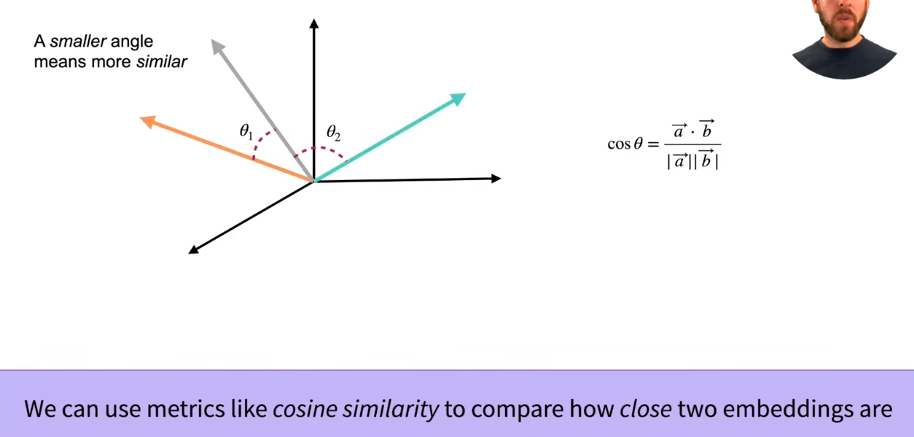

## What is in "puppy" word vector?
An embedding vector for "puppy" is a list of 768 decimal numbers (ranging roughly between -1.0 and +1.0), where each number acts like a tiny dial representing an abstract pattern learned by the AI. Individual numbers do not have fixed human labels like "cuteness" or "fur"—instead, meaning comes from the combined pattern of all 768 dials working together.


### 1. How to Print the Actual "puppy" Vector on Your Machine

Because nomic-embed-text runs locally on your computer, you can print the exact 768 numbers for "puppy" with this short script:


### 2. What Each Number Actually Represents

* **Positive numbers (+0.0921)** ==> A positive value means "puppy" strongly activates that specific hidden pattern (for instance, a pattern shared by living creatures or small animals).
* **Negative numbers (-0.0631)** ==> A negative value means "puppy" pushes away from that pattern (for example, patterns associated with inanimate machines or rocks).
* **Numbers near zero (0.0045)** ==> A value close to zero means that particular dial is neutral or irrelevant to the word "puppy".

### 3. Why Individual Dials Don't Have Human Names

* **AI-invented coordinates:** During training, nomic-embed-text read billions of sentences and invented its own 768-axis coordinate system to organize human knowledge as efficiently as possible.
* **Hared features across dimensions** Instead of dedicating Dial #1 to "Dog" and Dial #2 to "Young", the model spreads concepts across dozens of dials at once. That is why "puppy" and "dog" will have nearly matching numbers across most of the 768 positions, while "puppy" and "kitten" will match on the "young/cute" dials and differ slightly on the "canine vs. feline" dials.

### 4. Kid-Friendly Analogy: The 768-Slider Sound Mixer

* **Think of a giant music studio mixer:** Imagine a board with 768 volume sliders. To create the sound of "puppy", the AI slides Dial #1 up slightly, pulls Dial #2 down, pushes Dial #3 way up, and sets all 768 sliders to a unique recipe.
* **Matching recipes:** When you type "dog", the AI sets the 768 sliders into almost the exact same shape—only nudging a few "age/size" sliders slightly!


In [22]:
import json
import urllib.request

url = "http://localhost:11434/api/embed"
payload = json.dumps({"model": "nomic-embed-text", "input": "puppy"}).encode("utf-8")
req = urllib.request.Request(url, data=payload, headers={"Content-Type": "application/json"})

with urllib.request.urlopen(req) as response:
    (puppy_vec,) = json.loads(response.read().decode("utf-8"))["embeddings"]

print(f"Total dials (dimensions): {len(puppy_vec)}")
print("First 10 and Last 10 numbers:", [round(x, 4) for x in puppy_vec[:10]],"\n", [round(x, 4) for x in puppy_vec[-10:]])


Total dials (dimensions): 768
First 10 and Last 10 numbers: [-0.0126, 0.0185, -0.1493, -0.0139, 0.0173, 0.0205, -0.0537, 0.0029, 0.0213, -0.0761] 
 [0.0057, -0.0147, 0.0344, -0.0154, 0.007, -0.0029, -0.0354, -0.0108, -0.044, -0.0055]


----
----


# Cell 1: Fetch Vectors & Plot Their "Number Fingerprints"

This cell connects to your local nomic-embed-text model and draws the first 30 numbers of each sentence as a colorful barcode. Your kid can visually spot that S1 and S2 share matching color patterns, while S3 looks different.

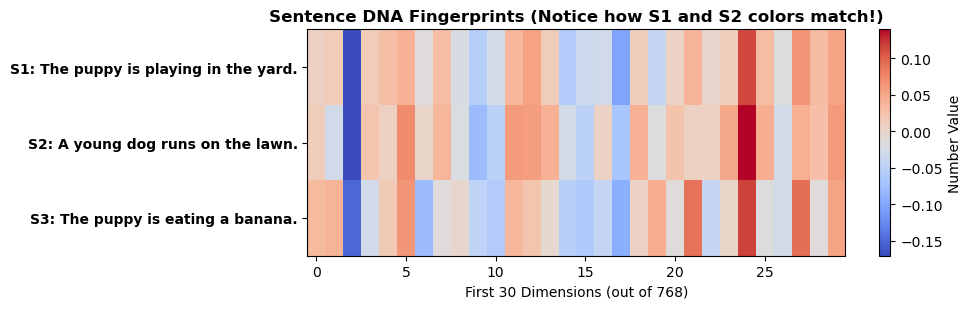

In [23]:
# %% Cell 1: Get Embeddings & Draw "Sentence Fingerprints"
import json
import urllib.request
import matplotlib.pyplot as plt
import numpy as np

sentences = [
    "S1: The puppy is playing in the yard.",
    "S2: A young dog runs on the lawn.",
    "S3: The puppy is eating a banana.",
]


def get_embeddings(texts):
    url = "http://localhost:11434/api/embed"
    payload = json.dumps({"model": "nomic-embed-text", "input": texts}).encode(
        "utf-8"
    )
    req = urllib.request.Request(
        url, data=payload, headers={"Content-Type": "application/json"}
    )
    with urllib.request.urlopen(req) as response:
        return np.array(json.loads(response.read().decode("utf-8"))["embeddings"])


vecs_768d = get_embeddings(sentences)
vec_s1, vec_s2, vec_s3 = vecs_768d

# Graphic: Visual Fingerprint (First 30 of 768 numbers)
fig, ax = plt.subplots(figsize=(10, 3.2))
heatmap = ax.imshow(vecs_768d[:, :30], cmap="coolwarm", aspect="auto")
ax.set_yticks([0, 1, 2])
ax.set_yticklabels(sentences, fontsize=10, fontweight="bold")
ax.set_xlabel("First 30 Dimensions (out of 768)", fontsize=10)
ax.set_title(
    "Sentence DNA Fingerprints (Notice how S1 and S2 colors match!)",
    fontsize=12,
    fontweight="bold",
)
plt.colorbar(heatmap, ax=ax, label="Number Value")
plt.tight_layout()
plt.show()



# Cell 2: Plot All Three Vectors Together on a "Meaning Compass"

This cell squashes all 768 dimensions down to 2D (X and Y) so we can draw all three sentences as arrows starting from the center (0, 0).

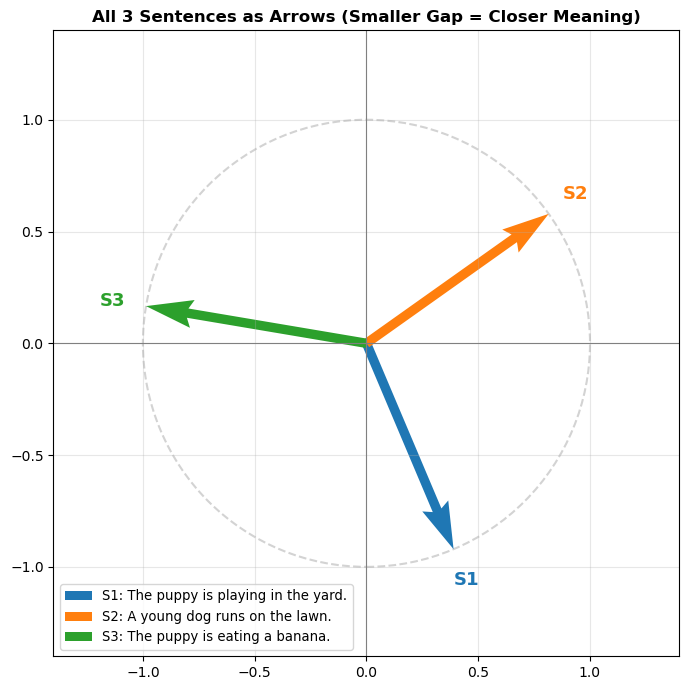

In [24]:
# %% Cell 2: Plot All 3 Vectors on One Compass
from sklearn.decomposition import PCA

# Compress 768D -> 2D and make every arrow length = 1.0
pca = PCA(n_components=2)
vecs_2d = pca.fit_transform(vecs_768d)
vecs_2d = vecs_2d / np.linalg.norm(vecs_2d, axis=1, keepdims=True)
arrow_1, arrow_2, arrow_3 = vecs_2d

fig, ax = plt.subplots(figsize=(7, 7))
circle = plt.Circle(
    (0, 0), 1.0, color="lightgray", fill=False, linestyle="--", linewidth=1.5
)
ax.add_patch(circle)

arrows = [arrow_1, arrow_2, arrow_3]
colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]

for arrow, label, color in zip(arrows, sentences, colors):
    x, y = arrow
    ax.quiver(
        0,
        0,
        x,
        y,
        angles="xy",
        scale_units="xy",
        scale=1,
        color=color,
        width=0.015,
        label=label,
    )
    ax.text(
        x * 1.15,
        y * 1.15,
        label[:2],
        color=color,
        fontsize=13,
        fontweight="bold",
        ha="center",
        va="center",
    )

ax.set_xlim(-1.4, 1.4)
ax.set_ylim(-1.4, 1.4)
ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_aspect("equal")
ax.set_title("All 3 Sentences as Arrows (Smaller Gap = Closer Meaning)", fontsize=12, fontweight="bold")
ax.legend(loc="lower left", fontsize=9.5)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



# Cell 3: Helper Function & Pair 1 (S1 vs S2 — Same Meaning)

This cell creates a reusable Angle + Similarity Meter chart and compares S1 (puppy playing) with S2 (young dog running). You will see a small shaded wedge between the arrows and a high score bar.

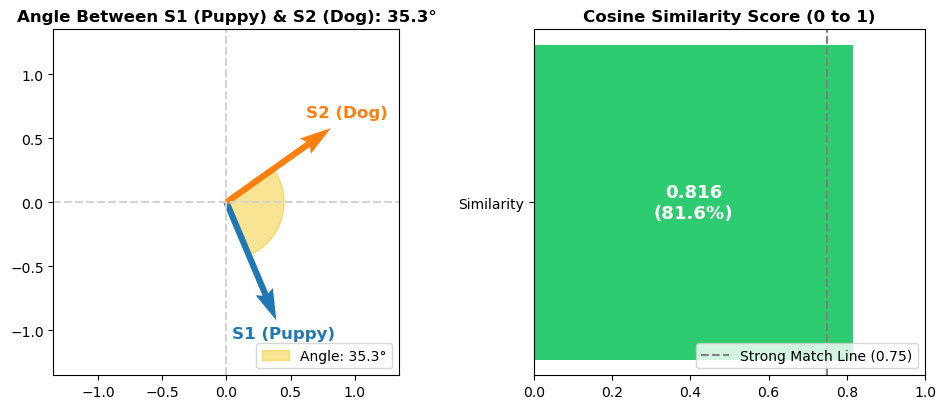

S1 (Puppy) vs S2 (Dog) -> Cosine Similarity = 0.8165 | Angle = 35.3°


In [25]:
# %% Cell 3: Compare S1 vs S2 (Similar Meaning)
from matplotlib.patches import Wedge


def plot_pair_comparison(
    v1_768, v2_768, a1_2d, a2_2d, name1, name2, color1, color2
):
    # Exact 768D cosine similarity & angle
    cos_sim = np.dot(v1_768, v2_768) / (
        np.linalg.norm(v1_768) * np.linalg.norm(v2_768)
    )
    angle_deg = np.degrees(np.arccos(np.clip(cos_sim, -1.0, 1.0)))

    fig, (ax1, ax2) = plt.subplots(
        1, 2, figsize=(10, 4.2), gridspec_kw={"width_ratios": [1.3, 1]}
    )

    # Left Graphic: Arrows + Angle Wedge
    ang1 = np.degrees(np.arctan2(a1_2d[1], a1_2d[0])) % 360
    ang2 = np.degrees(np.arctan2(a2_2d[1], a2_2d[0])) % 360
    diff = (ang2 - ang1) % 360
    start, end = (ang1, ang2) if diff <= 180 else (ang2, ang1)

    wedge = Wedge(
        (0, 0), 0.45, start, end, color="#f1c40f", alpha=0.45, label=f"Angle: {angle_deg:.1f}°"
    )
    ax1.add_patch(wedge)

    for a, name, c in [(a1_2d, name1, color1), (a2_2d, name2, color2)]:
        ax1.quiver(
            0, 0, a[0], a[1], angles="xy", scale_units="xy", scale=1, color=c, width=0.018
        )
        ax1.text(a[0] * 1.15, a[1] * 1.15, name, color=c, fontsize=12, fontweight="bold", ha="center")

    ax1.set_xlim(-1.35, 1.35)
    ax1.set_ylim(-1.35, 1.35)
    ax1.axhline(0, color="lightgray", linestyle="--")
    ax1.axvline(0, color="lightgray", linestyle="--")
    ax1.set_aspect("equal")
    ax1.set_title(f"Angle Between {name1} & {name2}: {angle_deg:.1f}°", fontweight="bold")
    ax1.legend(loc="lower right")

    # Right Graphic: Similarity Score Gauge
    bar_color = "#2ecc71" if cos_sim > 0.75 else "#e74c3c"
    ax2.barh(["Similarity"], [cos_sim], color=bar_color, height=0.4)
    ax2.set_xlim(0, 1.0)
    ax2.axvline(0.75, color="gray", linestyle="--", label="Strong Match Line (0.75)")
    ax2.text(
        cos_sim / 2,
        0,
        f"{cos_sim:.3f}\n({cos_sim*100:.1f}%)",
        color="white",
        fontsize=13,
        fontweight="bold",
        ha="center",
        va="center",
    )
    ax2.set_title("Cosine Similarity Score (0 to 1)", fontweight="bold")
    ax2.legend(loc="lower right")

    plt.tight_layout()
    plt.show()
    print(f"{name1} vs {name2} -> Cosine Similarity = {cos_sim:.4f} | Angle = {angle_deg:.1f}°")


plot_pair_comparison(
    vec_s1, vec_s2, arrow_1, arrow_2, "S1 (Puppy)", "S2 (Dog)", "#1f77b4", "#ff7f0e"
)


# Cell 4: Pair 2 (S1 vs S3 — Different Meaning, Shared Words)
This cell compares S1 (puppy playing) with S3 (puppy eating a banana). Even though both start with "The puppy is...", the shaded wedge opens much wider and the meter drops into the red zone.

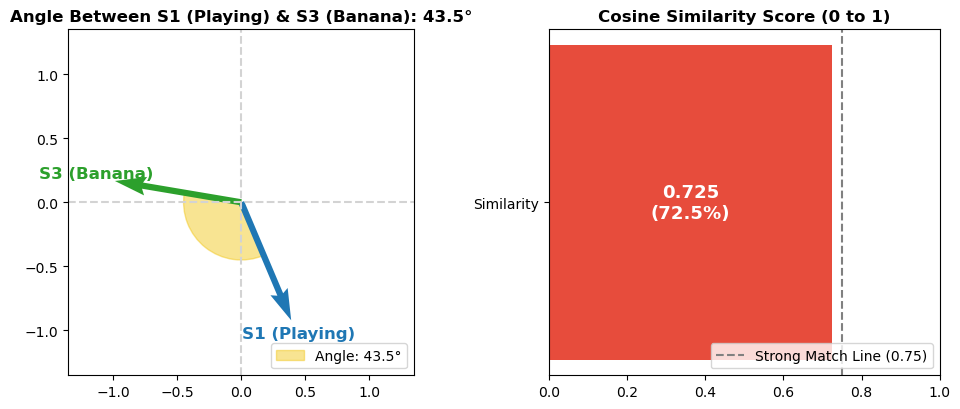

S1 (Playing) vs S3 (Banana) -> Cosine Similarity = 0.7255 | Angle = 43.5°


In [26]:
# %% Cell 4: Compare S1 vs S3 (Different Meaning)
plot_pair_comparison(
    vec_s1, vec_s3, arrow_1, arrow_3, "S1 (Playing)", "S3 (Banana)", "#1f77b4", "#2ca02c"
)



# Cell 5: Pair 3 (S2 vs S3) & Final Scorecard Grid

This cell calculates the final pair (S2 vs S3) and draws a complete 3x3 Scorecard Grid so you and your kid can compare every pair at a glance.

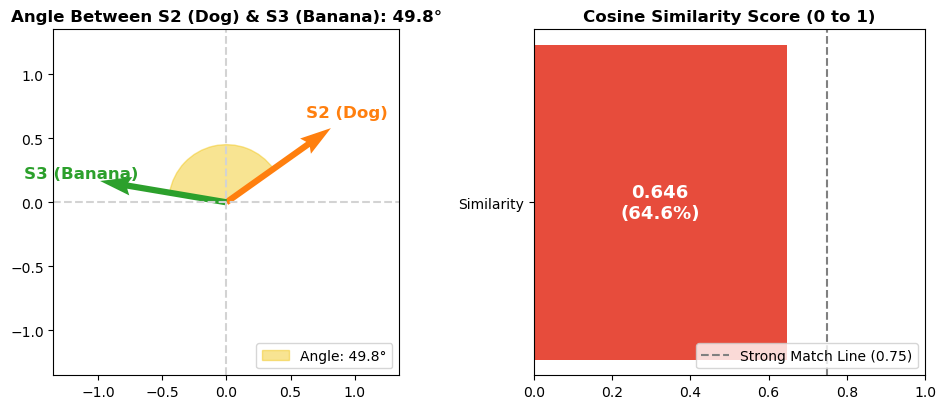

S2 (Dog) vs S3 (Banana) -> Cosine Similarity = 0.6460 | Angle = 49.8°


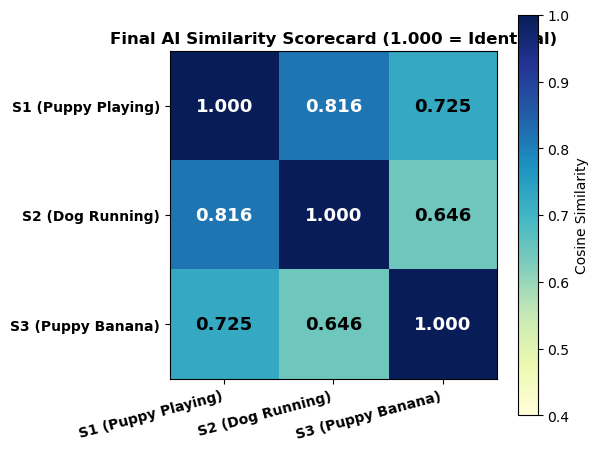

In [27]:
# %% Cell 5: Compare S2 vs S3 + Full 3x3 Scorecard
plot_pair_comparison(
    vec_s2, vec_s3, arrow_2, arrow_3, "S2 (Dog)", "S3 (Banana)", "#ff7f0e", "#2ca02c"
)

# Normalize all 768D vectors to compute the full 3x3 similarity table in one step
norms = np.linalg.norm(vecs_768d, axis=1, keepdims=True)
normalized_vecs = vecs_768d / norms
similarity_matrix = normalized_vecs @ normalized_vecs.T

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(similarity_matrix, cmap="YlGnBu", vmin=0.4, vmax=1.0)

short_labels = ["S1 (Puppy Playing)", "S2 (Dog Running)", "S3 (Puppy Banana)"]
ax.set_xticks([0, 1, 2])
ax.set_yticks([0, 1, 2])
ax.set_xticklabels(short_labels, rotation=15, ha="right", fontweight="bold")
ax.set_yticklabels(short_labels, fontweight="bold")

for row in range(3):
    for col in range(3):
        score = similarity_matrix[row, col]
        text_color = "white" if score > 0.75 else "black"
        ax.text(
            col, row, f"{score:.3f}", ha="center", va="center", color=text_color, fontsize=13, fontweight="bold"
        )

ax.set_title("Final AI Similarity Scorecard (1.000 = Identical)", fontsize=12, fontweight="bold")
plt.colorbar(im, ax=ax, label="Cosine Similarity")
plt.tight_layout()
plt.show()



### Kid-Friendly Takeaways to Point Out

* Cell 1 (Barcode): "Look at the colors—Sentence 1 and Sentence 2 have almost the same stripes even though they used different words!"
* Cell 3 vs. Cell 4 (Yellow Pizza Slice): "The yellow slice between S1 and S2 is skinny because they mean the same thing. The yellow slice between S1 and S3 is wide because eating a banana is totally different from playing in the yard."
* Cell 5 (Scorecard): "Any sentence compared with itself gets a perfect 1.000 down the diagonal."


---

# Word-level interactive notebook
Instead of only comparing full sentences, this version breaks sentences down into individual words, prints their actual vector numbers, calculates every Cosine Similarity + Angle (in degrees) between words, and plots how individual words cluster together by meaning!

* https://daniel.guetta.com/word2vec
* https://www.cs.cornell.edu/courses/cs4782/2026sp/demos/word2vec/
* https://www.cs.cmu.edu/~dst/WordEmbeddingDemo/
* https://www.cs.cmu.edu/~dst/WordEmbeddingDemo/tutorial.html
* https://www.cs.cmu.edu/~dst/WordEmbeddingDemo/EAAI-2022-Word-Embedding.pdf
* https://jalammar.github.io/illustrated-word2vec/


## Cell 1: Print Word Vectors & Draw Their "Word DNA Barcodes"

This cell embeds individual words from our sentences (plus a live word typed by your kid!), prints the first few numbers of every word's 768-dimensional vector, and draws a side-by-side color barcode.

Kid's Turn! Type ONE word and press Enter:  Kitten


=== RAW WORD VECTORS (First 6 of 768 numbers) ===
puppy      (768D): [-0.0126, +0.0185, -0.1493, -0.0139, +0.0173, +0.0205, ...]
dog        (768D): [+0.0028, -0.0114, -0.1614, -0.0433, +0.0460, +0.0589, ...]
yard       (768D): [+0.0627, +0.0154, -0.1809, +0.0234, +0.0203, +0.0216, ...]
lawn       (768D): [+0.0796, +0.0102, -0.1795, +0.0370, +0.0038, +0.0379, ...]
playing    (768D): [+0.0075, +0.0483, -0.2385, -0.0119, +0.0081, +0.0220, ...]
runs       (768D): [+0.0044, +0.0439, -0.2028, +0.0258, +0.0423, +0.0290, ...]
eating     (768D): [+0.0360, +0.0796, -0.1701, +0.0080, +0.0174, +0.0451, ...]
banana     (768D): [+0.0534, +0.0454, -0.1559, +0.0135, +0.0026, +0.0583, ...]
Kitten     (768D): [+0.0128, +0.0438, -0.1311, -0.0351, +0.0232, +0.0319, ...] <-- KID'S WORD


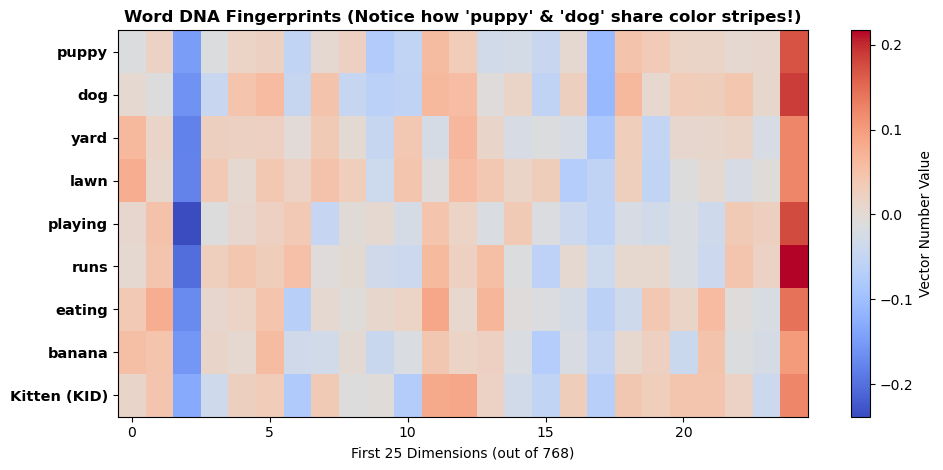

In [28]:
# %% Cell 1: Print Individual Word Vectors & Draw Word DNA Barcodes
import json
import urllib.request
import matplotlib.pyplot as plt
import numpy as np

# Key words from our sentences
base_words = ["puppy", "dog", "yard", "lawn", "playing", "runs", "eating", "banana"]

# Kid's Turn! Type a single word (e.g., "kitten", "apple", "park", "car")
kid_word = input("Kid's Turn! Type ONE word and press Enter: ").strip()
if not kid_word:
    kid_word = "kitten"

words = base_words + [kid_word]

def get_embeddings(texts):
    url = "http://localhost:11434/api/embed"
    payload = json.dumps({"model": "nomic-embed-text", "input": texts}).encode("utf-8")
    req = urllib.request.Request(url, data=payload, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req) as response:
        return np.array(json.loads(response.read().decode("utf-8"))["embeddings"])

word_vecs_768d = get_embeddings(words)

# 1. Print the actual vector numbers for each word
print("=== RAW WORD VECTORS (First 6 of 768 numbers) ===")
for w, vec in zip(words, word_vecs_768d):
    tag = " <-- KID'S WORD" if w == kid_word else ""
    preview = ", ".join([f"{n:+.4f}" for n in vec[:6]])
    print(f"{w:<10} (768D): [{preview}, ...]{tag}")

# 2. Pictorial View: Word DNA Fingerprints (First 25 dimensions)
fig, ax = plt.subplots(figsize=(10, 4.8))
heatmap = ax.imshow(word_vecs_768d[:, :25], cmap="coolwarm", aspect="auto")

display_labels = [f"{w} (KID)" if w == kid_word else w for w in words]
ax.set_yticks(range(len(words)))
ax.set_yticklabels(display_labels, fontsize=10.5, fontweight="bold")
ax.set_xlabel("First 25 Dimensions (out of 768)", fontsize=10)
ax.set_title("Word DNA Fingerprints (Notice how 'puppy' & 'dog' share color stripes!)", fontsize=12, fontweight="bold")
plt.colorbar(heatmap, ax=ax, label="Vector Number Value")
plt.tight_layout()
plt.show()



## Cell 2: Pictorial "Word Neighborhood" Map (All Words as Arrows)

This cell compresses the 768-dimensional word vectors down to 2D arrows so you and your kid can visually see word neighborhoods—animals point one way, places point another, and food points somewhere else!

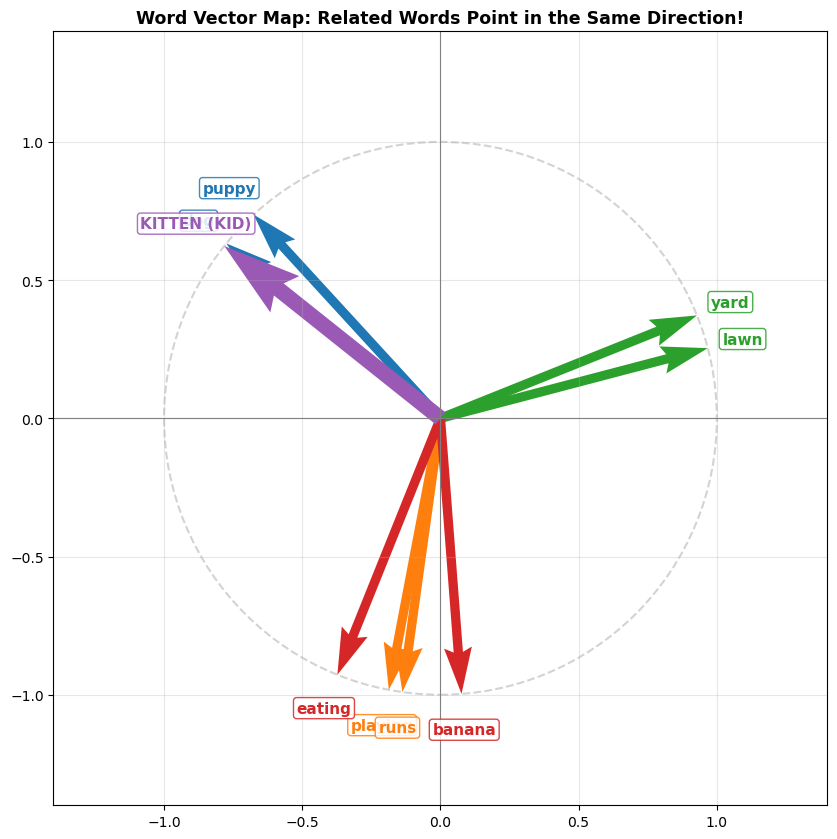

In [29]:
# %% Cell 2: Pictorial View of All Word Vectors (Meaning Compass)
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
word_vecs_2d = pca.fit_transform(word_vecs_768d)
word_vecs_2d = word_vecs_2d / np.linalg.norm(word_vecs_2d, axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(8.5, 8.5))
circle = plt.Circle((0, 0), 1.0, color="lightgray", fill=False, linestyle="--", linewidth=1.5)
ax.add_patch(circle)

# Color-code words by concept family
word_colors = {
    "puppy": "#1f77b4", "dog": "#1f77b4",       # Animals (Blue)
    "yard": "#2ca02c", "lawn": "#2ca02c",        # Places (Green)
    "playing": "#ff7f0e", "runs": "#ff7f0e",     # Actions (Orange)
    "eating": "#d62728", "banana": "#d62728",    # Food (Red)
}

for w, vec in zip(words, word_vecs_2d):
    x, y = vec[0], vec[1]
    is_kid = (w == kid_word)
    color = "#9b59b6" if is_kid else word_colors.get(w, "#34495e")
    width = 0.020 if is_kid else 0.012
    label_txt = f"{w.upper()} (KID)" if is_kid else w

    ax.quiver(0, 0, x, y, angles="xy", scale_units="xy", scale=1, color=color, width=width)
    ax.text(x * 1.13, y * 1.13, label_txt, color=color, fontsize=11,
            fontweight="bold", ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor=color, alpha=0.85))

ax.set_xlim(-1.4, 1.4)
ax.set_ylim(-1.4, 1.4)
ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_aspect("equal")
ax.set_title("Word Vector Map: Related Words Point in the Same Direction!", fontsize=12.5, fontweight="bold")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



## Cell 3: Word-to-Word Relationship Table (Cosine Values & Angles)

This cell prints a clear Word Relationship Table showing the exact Cosine Similarity and Angle in Degrees between key word pairs, plus ranks every word against your kid's chosen word.

In [30]:
# %% Cell 3: Print Exact Cosine Values & Angles Between Words
def word_stats(w1, w2):
    v1 = word_vecs_768d[words.index(w1)]
    v2 = word_vecs_768d[words.index(w2)]
    cos_sim = float(np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2)))
    angle_deg = float(np.degrees(np.arccos(np.clip(cos_sim, -1.0, 1.0))))
    return cos_sim, angle_deg

print("=== KEY WORD PAIR RELATIONSHIPS ===")
print(f"{'Word Pair':<22} | {'Cosine Sim':<12} | {'Angle':<10} | {'Meaning'}")
print("-" * 68)

pairs_to_check = [
    ("puppy", "dog", "Almost identical meaning!"),
    ("yard", "lawn", "Very close outdoor places"),
    ("playing", "runs", "Related active actions"),
    ("puppy", "banana", "Completely unrelated concepts"),
]

for w1, w2, note in pairs_to_check:
    sim, ang = word_stats(w1, w2)
    print(f"{w1 + ' <-> ' + w2:<22} | {sim:<12.4f} | {ang:>5.1f}°    | {note}")

print(f"\n=== HOW '{kid_word.upper()}' COMPARES TO EVERY WORD ===")
kid_rankings = []
for w in base_words:
    sim, ang = word_stats(kid_word, w)
    kid_rankings.append((sim, ang, w))

# Sort from highest similarity (smallest angle) to lowest
kid_rankings.sort(reverse=True)
for sim, ang, w in kid_rankings:
    print(f"{kid_word:<10} <-> {w:<10} | Cosine: {sim:.4f} | Angle: {ang:>5.1f}°")


=== KEY WORD PAIR RELATIONSHIPS ===
Word Pair              | Cosine Sim   | Angle      | Meaning
--------------------------------------------------------------------
puppy <-> dog          | 0.7897       |  37.8°    | Almost identical meaning!
yard <-> lawn          | 0.8253       |  34.4°    | Very close outdoor places
playing <-> runs       | 0.5911       |  53.8°    | Related active actions
puppy <-> banana       | 0.3617       |  68.8°    | Completely unrelated concepts

=== HOW 'KITTEN' COMPARES TO EVERY WORD ===
Kitten     <-> puppy      | Cosine: 0.6092 | Angle:  52.5°
Kitten     <-> dog        | Cosine: 0.5783 | Angle:  54.7°
Kitten     <-> playing    | Cosine: 0.5263 | Angle:  58.2°
Kitten     <-> runs       | Cosine: 0.4536 | Angle:  63.0°
Kitten     <-> eating     | Cosine: 0.4380 | Angle:  64.0°
Kitten     <-> yard       | Cosine: 0.4351 | Angle:  64.2°
Kitten     <-> lawn       | Cosine: 0.4341 | Angle:  64.3°
Kitten     <-> banana     | Cosine: 0.4267 | Angle:  64.7°


## Cell 4: Pictorial Side-by-Side Angle Wedges for Word Pairs

This cell draws 4 visual protractor wedges comparing puppy <-> dog, yard <-> lawn, puppy <-> banana, and your kid's word against its #1 closest match!

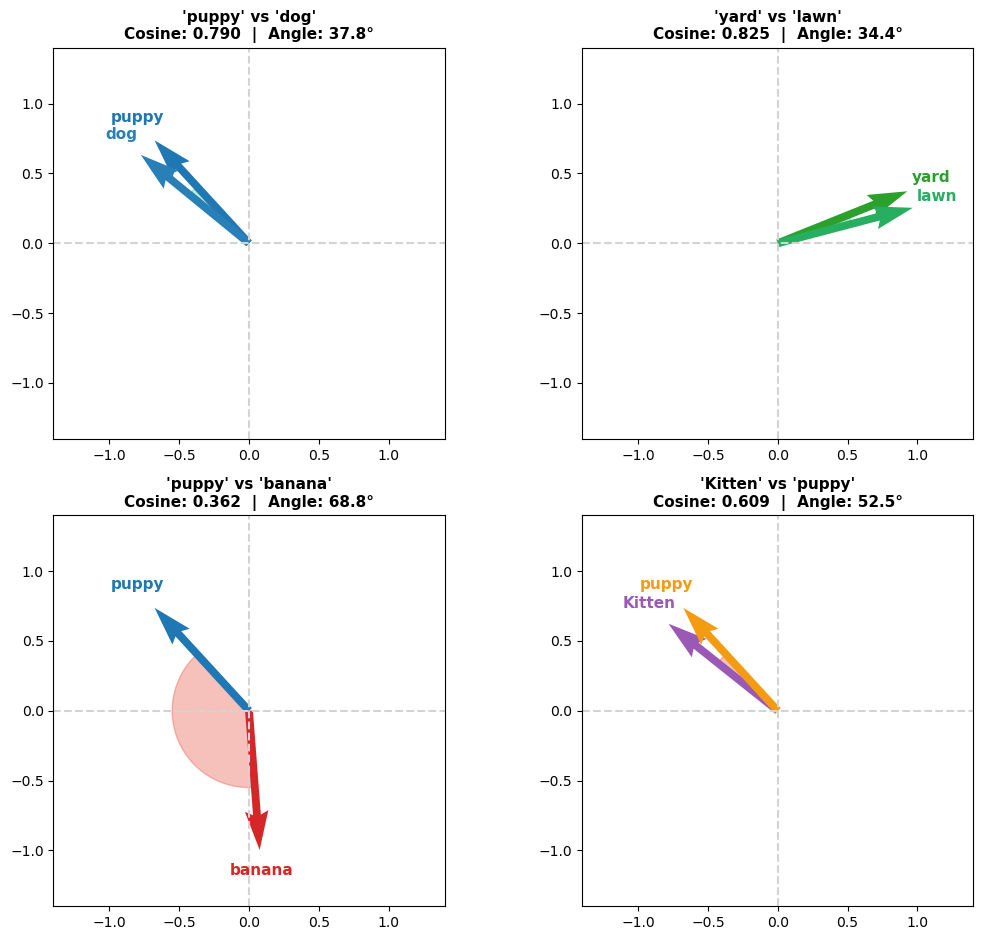

In [31]:
# %% Cell 4: Pictorial Angle Wedges for Word Pairs
from matplotlib.patches import Wedge

best_match_word = kid_rankings[0][2]  # Closest word to kid's word

visual_pairs = [
    ("puppy", "dog", "#1f77b4", "#2980b9"),
    ("yard", "lawn", "#2ca02c", "#27ae60"),
    ("puppy", "banana", "#1f77b4", "#d62728"),
    (kid_word, best_match_word, "#9b59b6", "#f39c12"),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 9.5))
axes = axes.flatten()

for ax, (w1, w2, c1, c2) in zip(axes, visual_pairs):
    sim, ang = word_stats(w1, w2)
    a1 = word_vecs_2d[words.index(w1)]
    a2 = word_vecs_2d[words.index(w2)]

    deg1 = np.degrees(np.arctan2(a1[1], a1[0])) % 360
    deg2 = np.degrees(np.arctan2(a2[1], a2[0])) % 360
    diff = (deg2 - deg1) % 360
    start, end = (deg1, deg2) if diff <= 180 else (deg2, deg1)

    # Shaded angle slice
    wedge_color = "#2ecc71" if sim > 0.70 else "#e74c3c"
    ax.add_patch(Wedge((0, 0), 0.55, start, end, color=wedge_color, alpha=0.35))

    for a, name, c in [(a1, w1, c1), (a2, w2, c2)]:
        ax.quiver(0, 0, a[0], a[1], angles="xy", scale_units="xy", scale=1, color=c, width=0.02)
        ax.text(a[0] * 1.18, a[1] * 1.18, name, color=c, fontsize=11, fontweight="bold", ha="center")

    ax.set_xlim(-1.4, 1.4)
    ax.set_ylim(-1.4, 1.4)
    ax.axhline(0, color="lightgray", linestyle="--")
    ax.axvline(0, color="lightgray", linestyle="--")
    ax.set_aspect("equal")
    ax.set_title(f"'{w1}' vs '{w2}'\nCosine: {sim:.3f}  |  Angle: {ang:.1f}°", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()


## Cell 5: Complete Word-to-Word Heatmap Grid (All Cosine Values)

This final cell creates a complete 9x9 Word Relationship Matrix so your kid can pick any row and any column to see how strongly two words connect.

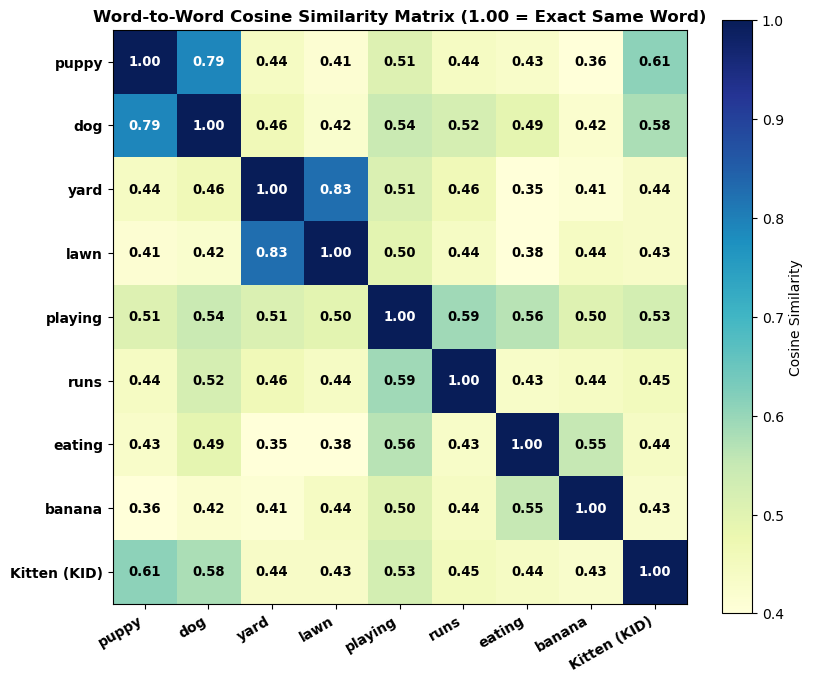

In [32]:
# %% Cell 5: Complete Word-to-Word Cosine Similarity Matrix
norms = np.linalg.norm(word_vecs_768d, axis=1, keepdims=True)
norm_vecs = word_vecs_768d / norms
word_sim_matrix = norm_vecs @ norm_vecs.T

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(word_sim_matrix, cmap="YlGnBu", vmin=0.4, vmax=1.0)

ax.set_xticks(range(len(words)))
ax.set_yticks(range(len(words)))
ax.set_xticklabels(display_labels, rotation=30, ha="right", fontweight="bold")
ax.set_yticklabels(display_labels, fontweight="bold")

for r in range(len(words)):
    for c in range(len(words)):
        val = word_sim_matrix[r, c]
        txt_color = "white" if val > 0.75 else "black"
        ax.text(c, r, f"{val:.2f}", ha="center", va="center", color=txt_color, fontsize=9.5, fontweight="bold")

ax.set_title("Word-to-Word Cosine Similarity Matrix (1.00 = Exact Same Word)", fontsize=12, fontweight="bold")
plt.colorbar(im, ax=ax, label="Cosine Similarity")
plt.tight_layout()
plt.show()


# Why Cosine Similarity Instead of Sine?

**We use cosine instead of sine because cosine gives `1` (maximum similarity) when two arrows point in the exact same direction (`0°` angle), whereas sine gives `0`.** Furthermore, cosine is super fast for computers to calculate using simple multiplication and addition, while sine requires slow, complex geometry math.

---

## 1. The Score Direction Matches Human Intuition
When two sentences or words have the exact same meaning, their arrows point in the **same direction**, creating an angle of **`0°`**:

* **Cosine at `0°` = `1.0`.** A higher score (`1.0`) naturally means a better match (100% similar).
* **Sine at `0°` = `0.0`.** Using sine would give identical words a score of `0`, and totally unrelated words (`90°`) a score of `1`, which feels completely backwards.

---

## 2. Cosine Is Blazingly Fast to Compute
* **Simple dot product.** The formula for cosine is directly built into basic vector multiplication:
  $$\cos \theta = \frac{\vec{a} \cdot \vec{b}}{\|\vec{a}\|\|\vec{b}\|}$$
  Computers only need to multiply and add numbers together—no trigonometry tables required.
* **Works easily in 768 dimensions.** Finding sine in high dimensions requires computing cross-products or geometric areas, which becomes mathematically messy beyond 3 dimensions. Cosine works identically whether you have 2 numbers or 768 numbers.

---

## 3. Comparison Table: Cosine vs. Sine

| Angle Between Arrows | Meaning Relationship | **Cosine Score** (Used in AI) | **Sine Score** (Not Used) |
| :--- | :--- | :--- | :--- |
| **`0°`** (Same direction) | Identical meaning (`puppy` vs `puppy`) | **`1.00`** (Max score) | **`0.00`** (Zero!) |
| **`30°`** (Very close) | Strong match (`puppy` vs `dog`) | **`0.87`** (High score) | **`0.50`** (Low score) |
| **`45°`** (Close direction) | Related meaning (`puppy` vs `kitten`) | **`0.71`** (Good match) | **`0.71`** (Confusingly identical) |
| **`90°`** (Perpendicular) | Unrelated meaning (`puppy` vs `banana`) | **`0.00`** (Zero match) | **`1.00`** (Max score!) |

---

## 4. Kid-Friendly Analogy: The Flashlight Beam
* **Overlapping light.** Imagine two flashlights pointing straight ahead (`0°` apart). Their beams overlap **100%** ($\cos(0^\circ) = 1$).
* **Sideways light.** If you turn one flashlight sideways (`90°` apart), their beams do not overlap at all ($\cos(90^\circ) = 0$).
* **The takeaway.** Cosine measures **how much two ideas overlap** in the same direction!


---
---
# What we Will See on the Graph

* **Left side (0° — Identical words)**: The Cosine curve starts right at the top (1.00), while the Sine curve sits at the bottom (0.00).
* **Middle (~35°–45° — puppy vs. dog)**: The blue dot sits high up on the Cosine line, showing a strong match.
* **Right side (~60°–75° — puppy vs. banana)**: The red dot slides down the Cosine hill toward zero, while the gray Sine curve climbs up—proving visually why Sine would accidentally give unrelated words a higher score!


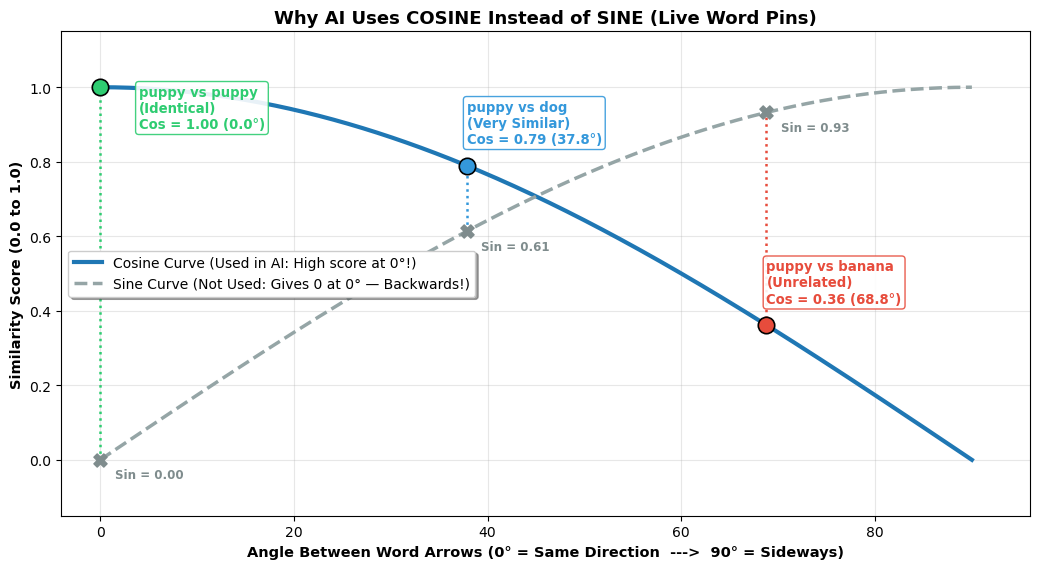

In [33]:
# %% Cell: Visual Comparison — Why AI Uses Cosine Instead of Sine
import json
import urllib.request
import matplotlib.pyplot as plt
import numpy as np

# 1. Fetch live embeddings from your local Ollama model
words_to_test = ["puppy", "dog", "banana"]


def get_embeddings(texts):
    url = "http://localhost:11434/api/embed"
    payload = json.dumps({"model": "nomic-embed-text", "input": texts}).encode(
        "utf-8"
    )
    req = urllib.request.Request(
        url, data=payload, headers={"Content-Type": "application/json"}
    )
    with urllib.request.urlopen(req) as response:
        return np.array(json.loads(response.read().decode("utf-8"))["embeddings"])


vecs = get_embeddings(words_to_test)
v_puppy, v_dog, v_banana = vecs


def get_angle_deg(v1, v2):
    cos_sim = np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))
    return float(np.degrees(np.arccos(np.clip(cos_sim, -1.0, 1.0))))


# 2. Calculate real angles between word pairs
pairs = [
    ("puppy vs puppy\n(Identical)", get_angle_deg(v_puppy, v_puppy), "#2ecc71"),
    ("puppy vs dog\n(Very Similar)", get_angle_deg(v_puppy, v_dog), "#3498db"),
    ("puppy vs banana\n(Unrelated)", get_angle_deg(v_puppy, v_banana), "#e74c3c"),
]

# 3. Generate smooth Cosine and Sine curves from 0° to 90°
angles = np.linspace(0, 90, 300)
radians = np.radians(angles)
cos_curve = np.cos(radians)
sin_curve = np.sin(radians)

fig, ax = plt.subplots(figsize=(10.5, 5.8))

# Plot Cosine (Green/Blue solid line) vs Sine (Gray dashed line)
ax.plot(
    angles,
    cos_curve,
    color="#1f77b4",
    linewidth=3,
    label="Cosine Curve (Used in AI: High score at 0°!)",
)
ax.plot(
    angles,
    sin_curve,
    color="#95a5a6",
    linewidth=2.5,
    linestyle="--",
    label="Sine Curve (Not Used: Gives 0 at 0° — Backwards!)",
)

# 4. Pin each word pair onto both curves
for label, deg, color in pairs:
    rad = np.radians(deg)
    c_val = np.cos(rad)
    s_val = np.sin(rad)

    # Vertical dashed guide line connecting the two curves at this angle
    ax.vlines(deg, min(c_val, s_val), max(c_val, s_val), color=color, linestyle=":", linewidth=1.8)

    # Pin on Cosine Curve (Big Star/Circle)
    ax.scatter(deg, c_val, color=color, s=140, zorder=5, edgecolors="black", linewidth=1.2)
    offset_y = -0.11 if deg < 10 else 0.06
    offset_x = 4 if deg < 10 else 0
    ax.annotate(
        f"{label}\nCos = {c_val:.2f} ({deg:.1f}°)",
        xy=(deg, c_val),
        xytext=(deg + offset_x, c_val + offset_y),
        fontsize=9.5,
        fontweight="bold",
        color=color,
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=color, alpha=0.9),
    )

    # Pin on Sine Curve (Small X mark)
    ax.scatter(deg, s_val, color="#7f8c8d", marker="X", s=90, zorder=5)
    ax.text(
        deg + 1.5,
        s_val - 0.05,
        f"Sin = {s_val:.2f}",
        fontsize=8.5,
        color="#7f8c8d",
        fontweight="bold",
    )

# Styling & Kid-Friendly Labels
ax.set_xlim(-4, 96)
ax.set_ylim(-0.15, 1.15)
ax.set_xlabel("Angle Between Word Arrows (0° = Same Direction  --->  90° = Sideways)", fontsize=10.5, fontweight="bold")
ax.set_ylabel("Similarity Score (0.0 to 1.0)", fontsize=10.5, fontweight="bold")
ax.set_title(
    "Why AI Uses COSINE Instead of SINE (Live Word Pins)",
    fontsize=13,
    fontweight="bold",
)
ax.legend(loc="center left", fontsize=10, frameon=True, shadow=True)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


---
---

# How things fed into AI

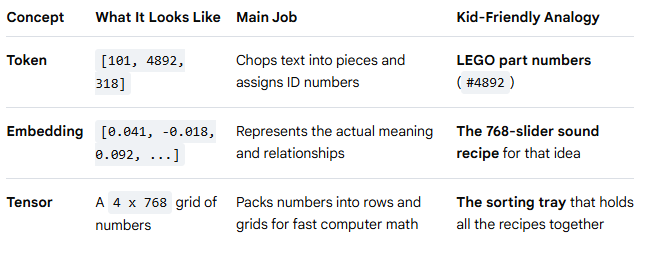

In [34]:
'''
  [1. RAW TEXT]          "The puppy plays"
                                 │
                                 ▼  (Tokenizer chops words into catalog IDs)
  [2. TOKENS]            [ 101 ]   [ 4892 ]   [ 7341 ]       <-- 1D list of 3 ID numbers
                         ("The")   ("puppy")  ("plays")
                                 │
                                 ▼  (Embedding Model looks up 768 meaning dials)
  [3. EMBEDDINGS]        "puppy" ──► [ +0.041, -0.018, +0.092, ... ]  (768 numbers)
                                 │
                                 ▼  (Stacked into a grid for fast AI math)
  [4. 2D TENSOR]         ┌────────────────────────────────────────┐
    Shape: (3, 768)      │ Row 0 ("The"):   [ 0.012, -0.044, ... ] │
                         │ Row 1 ("puppy"): [ 0.041, -0.018, ... ] │
                         │ Row 2 ("plays"): [-0.029,  0.067, ... ] │
                         └────────────────────────────────────────┘
'''

'\n  [1. RAW TEXT]          "The puppy plays"\n                                 │\n                                 ▼  (Tokenizer chops words into catalog IDs)\n  [2. TOKENS]            [ 101 ]   [ 4892 ]   [ 7341 ]       <-- 1D list of 3 ID numbers\n                         ("The")   ("puppy")  ("plays")\n                                 │\n                                 ▼  (Embedding Model looks up 768 meaning dials)\n  [3. EMBEDDINGS]        "puppy" ──► [ +0.041, -0.018, +0.092, ... ]  (768 numbers)\n                                 │\n                                 ▼  (Stacked into a grid for fast AI math)\n  [4. 2D TENSOR]         ┌────────────────────────────────────────┐\n    Shape: (3, 768)      │ Row 0 ("The"):   [ 0.012, -0.044, ... ] │\n                         │ Row 1 ("puppy"): [ 0.041, -0.018, ... ] │\n                         │ Row 2 ("plays"): [-0.029,  0.067, ... ] │\n                         └────────────────────────────────────────┘\n'

# Do All AI Models Use the Same Tokens, Embeddings, and Tensors?

**Almost all modern generative AI models—including text chatbots, image generators, voice assistants, and video models—use tensors and embeddings, though they use different "tokenizing" methods depending on the type of data.** While the underlying math engine (tensors + embeddings) is universal across modern deep learning, the way raw input gets chopped into tokens changes for pictures, audio, and text.

---

## 1. Tensors: Universal Across All Modern AI
* **Every neural network runs on tensors.** Whether you are running Llama, ChatGPT, Midjourney, or a self-driving car's vision system, the computer always packs numbers into multi-dimensional grids (**tensors**) because GPUs are specifically built to multiply tensors at massive speeds.
* **No exceptions in modern deep learning.** Classic rule-based programs (`if/else` code) or simple decision trees do not use tensors, but virtually every modern AI model does.

---

## 2. Embeddings: Universal for Meaning
* **Everything becomes a list of coordinates.** Modern AI cannot understand raw words, pixels, or sound waves directly—it converts everything into dense number lists (**embeddings**) so it can measure similarity and relationships.
* **Different dial counts.** Smaller models like `nomic-embed-text` use **768 numbers** per embedding, while massive language models (like Llama 3 or GPT-4) use **4,096 to 12,288+ numbers** per token to capture much finer details.

---

## 3. Tokens: How Different AI Models Chop Data
Every type of AI has its own style of "tokenizer" to turn raw data into numbered pieces before creating embeddings:

| AI Type | What Gets "Tokenized"? | How It Works |
| :--- | :--- | :--- |
| **Text AI** (Llama, Gemma, GPT) | **Word pieces** (Subwords) | Chops sentences into words or syllables (e.g., `"playing"` → `"play"` + `"ing"`). |
| **Image AI** (Vision Transformers, Flux) | **Image patches** (Tiny squares) | Slices a photo into a grid of small squares (like `16×16` pixels) and treats each square like a "visual token". |
| **Audio / Voice AI** (Whisper, Suno) | **Sound slices** (Audio frames) | Chops sound waves into tiny time slices (e.g., 20 milliseconds each) and turns each slice into an audio token. |
| **Video AI** (Sora, Veo) | **3D cubes** (Spacetime patches) | Slices video across both space (width/height) and time (frames) into tiny 3D blocks. |
| **Byte / Token-Free AI** (Experimental) | **Raw bytes or pixels** | A few newer experimental models skip word dictionaries and read raw UTF-8 bytes (`0–255`) directly, though they still turn those bytes into embeddings and tensors. |

---

## 4. Kid-Friendly Summary: Different Cutters, Same Kitchen
* Whether you feed the AI a **book** (chopped into word pieces), a **photo** (chopped into tiny puzzle squares), or a **song** (chopped into tiny sound clips), once it enters the AI's brain, **everything turns into Embeddings packed inside Tensors!**


=== INSPECTING THE SHAPES ===
1. Token for 'puppy'   -> ID #4892 (Just 1 catalog number)
2. Embedding ('puppy') -> 1D Vector | Shape: (768,)
3. Full Sentence Grid  -> 2D Tensor | Shape: (3, 768) (3 tokens x 768 dials)


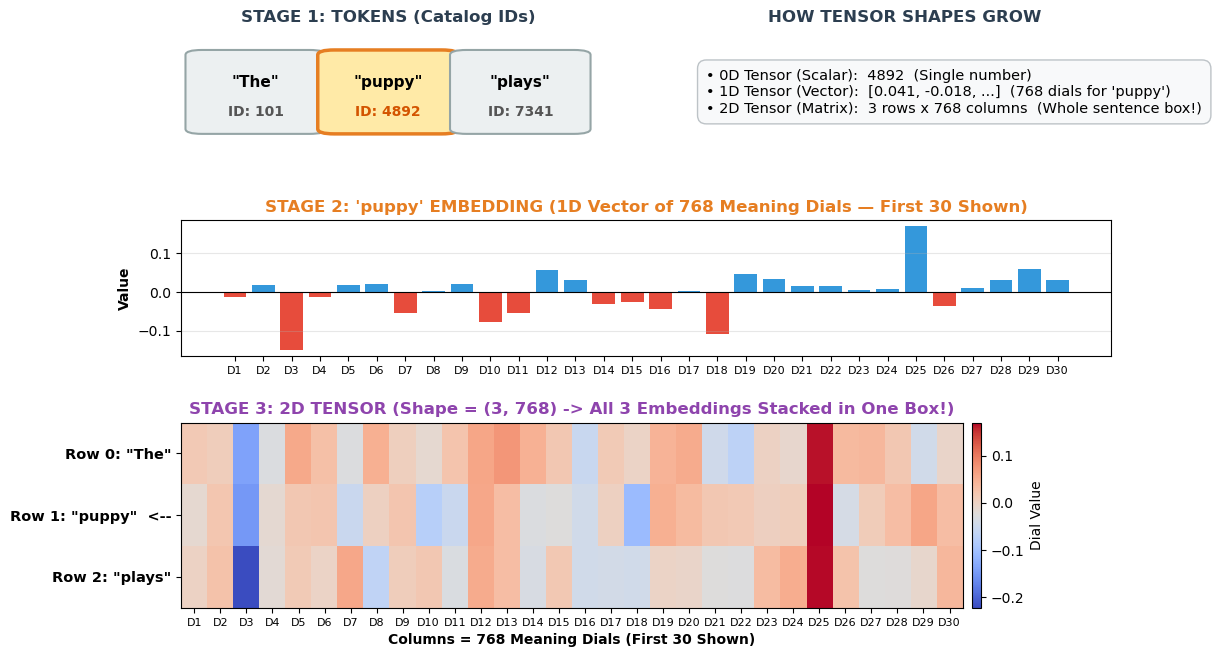

In [35]:
# %% Cell: Pictorial View of Tokens -> Embeddings -> Tensors ("puppy" Example)
import json
import urllib.request
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np

# 1. Fetch real 768D embeddings from Ollama for 3 tokens in "The puppy plays"
tokens_text = ["The", "puppy", "plays"]
fake_token_ids = [101, 4892, 7341]  # Illustrative dictionary IDs


def get_embeddings(texts):
    url = "http://localhost:11434/api/embed"
    payload = json.dumps({"model": "nomic-embed-text", "input": texts}).encode(
        "utf-8"
    )
    req = urllib.request.Request(
        url, data=payload, headers={"Content-Type": "application/json"}
    )
    with urllib.request.urlopen(req) as response:
        return np.array(json.loads(response.read().decode("utf-8"))["embeddings"])


# This 3 x 768 grid IS a 2D Tensor!
tensor_2d = get_embeddings(tokens_text)
puppy_embedding = tensor_2d[1]  # Row 1 is "puppy" (a 1D Vector of 768 numbers)

print("=== INSPECTING THE SHAPES ===")
print(f"1. Token for 'puppy'   -> ID #{fake_token_ids[1]} (Just 1 catalog number)")
print(
    f"2. Embedding ('puppy') -> {puppy_embedding.ndim}D Vector | Shape: {puppy_embedding.shape}"
)
print(
    f"3. Full Sentence Grid  -> {tensor_2d.ndim}D Tensor | Shape: {tensor_2d.shape} (3 tokens x 768 dials)"
)

# 2. Draw a 4-Stage Visual Flowchart
fig = plt.figure(figsize=(12, 7.5))
gs = fig.add_gridspec(3, 2, height_ratios=[1, 1.1, 1.5], hspace=0.45, wspace=0.25)

# --- STAGE 1: TOKENS (Top Left) ---
ax_tok = fig.add_subplot(gs[0, 0])
ax_tok.axis("off")
ax_tok.set_title("STAGE 1: TOKENS (Catalog IDs)", fontweight="bold", color="#2c3e50")

for i, (word, tid) in enumerate(zip(tokens_text, fake_token_ids)):
    is_puppy = word == "puppy"
    box_color = "#ffeaa7" if is_puppy else "#ecf0f1"
    edge_color = "#e67e22" if is_puppy else "#95a5a6"
    rect = patches.FancyBboxPatch(
        (0.05 + i * 0.32, 0.2),
        0.26,
        0.6,
        boxstyle="round,pad=0.04",
        facecolor=box_color,
        edgecolor=edge_color,
        linewidth=2.5 if is_puppy else 1.5,
    )
    ax_tok.add_patch(rect)
    ax_tok.text(
        0.18 + i * 0.32,
        0.58,
        f'"{word}"',
        ha="center",
        va="center",
        fontweight="bold",
        fontsize=11,
    )
    ax_tok.text(
        0.18 + i * 0.32,
        0.34,
        f"ID: {tid}",
        ha="center",
        va="center",
        color="#d35400" if is_puppy else "#555",
        fontweight="bold",
    )

# --- STAGE 2: 0D SCALAR vs 1D VECTOR EXPLAINER (Top Right) ---
ax_info = fig.add_subplot(gs[0, 1])
ax_info.axis("off")
ax_info.set_title("HOW TENSOR SHAPES GROW", fontweight="bold", color="#2c3e50")
summary_text = (
    "• 0D Tensor (Scalar):  4892  (Single number)\n"
    "• 1D Tensor (Vector):  [0.041, -0.018, ...]  (768 dials for 'puppy')\n"
    "• 2D Tensor (Matrix):  3 rows x 768 columns  (Whole sentence box!)"
)
ax_info.text(
    0.02,
    0.5,
    summary_text,
    va="center",
    fontsize=10.5,
    bbox=dict(boxstyle="round,pad=0.6", facecolor="#f8f9fa", edgecolor="#bdc3c7"),
)

# --- STAGE 3: SINGLE EMBEDDING FOR "puppy" (Middle Full Width) ---
ax_emb = fig.add_subplot(gs[1, :])
bars = ax_emb.bar(
    range(30),
    puppy_embedding[:30],
    color=["#3498db" if v >= 0 else "#e74c3c" for v in puppy_embedding[:30]],
)
ax_emb.axhline(0, color="black", linewidth=0.8)
ax_emb.set_xticks(range(30))
ax_emb.set_xticklabels([f"D{i+1}" for i in range(30)], fontsize=8)
ax_emb.set_ylabel("Value", fontweight="bold")
ax_emb.set_title(
    "STAGE 2: 'puppy' EMBEDDING (1D Vector of 768 Meaning Dials — First 30 Shown)",
    fontweight="bold",
    color="#e67e22",
)
ax_emb.grid(axis="y", alpha=0.3)

# --- STAGE 4: 2D TENSOR STACK (Bottom Full Width) ---
ax_ten = fig.add_subplot(gs[2, :])
im = ax_ten.imshow(tensor_2d[:, :30], cmap="coolwarm", aspect="auto")
ax_ten.set_yticks([0, 1, 2])
ax_ten.set_yticklabels(
    ['Row 0: "The"', 'Row 1: "puppy"  <--', 'Row 2: "plays"'],
    fontweight="bold",
    fontsize=10.5,
)
ax_ten.set_xticks(range(30))
ax_ten.set_xticklabels([f"D{i+1}" for i in range(30)], fontsize=8)
ax_ten.set_xlabel("Columns = 768 Meaning Dials (First 30 Shown)", fontweight="bold")
ax_ten.set_title(
    f"STAGE 3: 2D TENSOR (Shape = {tensor_2d.shape} -> All 3 Embeddings Stacked in One Box!)",
    fontweight="bold",
    color="#8e44ad",
)
plt.colorbar(im, ax=ax_ten, orientation="vertical", pad=0.01, label="Dial Value")

plt.show()
